In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness

sns.set_theme(style="whitegrid"); plt.rcParams.update({'font.size': 10})
                   
DATA_PATH = '/kaggle/input/datasets/caceelizaalexandra/tabel-date/tabel_aliniat_CP1_Cace (1).csv'

df = pd.read_csv(DATA_PATH, parse_dates=['date'])

# Setul de date conține exclusiv ianuarie, februarie și iunie–august.
# Iarna: ianuarie–februarie.
# Vara: iunie–august.
df['sezon'] = df['date'].dt.month.map({
    1: 'iarna',
    2: 'iarna',
    6: 'vara',
    7: 'vara',
    8: 'vara'
})

GRUPURI = {'Sensor.Community': ['PM2.5', 'PM10'],
           'ERA5': ['temperatura', 'umiditate_punct_roua', 'viteza_vant', 'boundary_layer_height', 'presiune_suprafata'],
           'S5P': ['NO2_satelit']}
TOATE = [c for g in GRUPURI.values() for c in g]
METEO = GRUPURI['ERA5']

n_senz, n_zile = df['sensor_id'].nunique(), df['date'].nunique()
posibile = n_senz * n_zile
print(f"Matricea X: n = {len(df)} observații (senzor × zi), d = {len(TOATE)} trăsături")
print(f"{n_senz} senzori × {n_zile} zile = {posibile} posibile; prezente {len(df)} ({len(df)/posibile:.1%})")
print(f"Iarnă: {df.loc[df.sezon=='iarna','date'].nunique()} zile · Vară: {df.loc[df.sezon=='vara','date'].nunique()} zile")

Matricea X: n = 1397 observații (senzor × zi), d = 8 trăsături
10 senzori × 151 zile = 1510 posibile; prezente 1397 (92.5%)
Iarnă: 59 zile · Vară: 92 zile


In [3]:
PROV = {  # trăsătură: (unitate, derivare, transformare)
 'PM2.5': ('µg/m³', 'Sensor.Community: medie zilnică (UTC) a măsurătorilor valide', 'log1p → standardizare'),
 'PM10':  ('µg/m³', 'Sensor.Community: medie zilnică (UTC) a măsurătorilor valide', 'log1p → standardizare'),
 'temperatura': ('°C', 'ERA5 t2m: medie zilnică a valorilor orare, medie pe 2 puncte de grilă', 'standardizare'),
 'umiditate_punct_roua': ('°C', 'ERA5 d2m: medie zilnică a valorilor orare, 2 puncte de grilă', 'standardizare'),
 'viteza_vant': ('m/s', 'ERA5 u10, v10: modul orar, apoi medie zilnică', 'standardizare'),
 'boundary_layer_height': ('m', 'ERA5 blh: medie zilnică a valorilor orare', 'standardizare'),
 'presiune_suprafata': ('Pa', 'ERA5 sp: medie zilnică a valorilor orare', 'standardizare'),
 'NO2_satelit': ('µmol/m²', 'S5P TROPOMI (colecția OFFL), GEE: coloană troposferică, medie urbană; negative trunchiate la 0', '×10⁶ → log1p → standardizare'),
}
meta = pd.DataFrame([(c, s, *PROV[c]) for s, cs in GRUPURI.items() for c in cs],
                    columns=['trasatura', 'sursa', 'unitate', 'derivare', 'transformare'])
for nume, mask in [('lipsa_%', slice(None)), ('lipsa_iarna_%', df.sezon == 'iarna'), ('lipsa_vara_%', df.sezon == 'vara')]:
    sub = df if nume == 'lipsa_%' else df[mask]
    meta[nume] = [round(sub[c].isna().mean() * 100, 1) for c in meta.trasatura]
meta.to_csv( 'cp2_matrice_X_documentata.csv', index=False); display(meta)

,trasatura,sursa,unitate,derivare,transformare,lipsa_%,lipsa_iarna_%,lipsa_vara_%
0,PM2.5,Sensor.Community,µg/m³,Sensor.Community: medie zilnică (UTC) a măsură...,log1p → standardizare,0.0,0.0,0.0
1,PM10,Sensor.Community,µg/m³,Sensor.Community: medie zilnică (UTC) a măsură...,log1p → standardizare,0.0,0.0,0.0
2,temperatura,ERA5,°C,"ERA5 t2m: medie zilnică a valorilor orare, med...",standardizare,0.0,0.0,0.0
3,umiditate_punct_roua,ERA5,°C,"ERA5 d2m: medie zilnică a valorilor orare, 2 p...",standardizare,0.0,0.0,0.0
4,viteza_vant,ERA5,m/s,"ERA5 u10, v10: modul orar, apoi medie zilnică",standardizare,0.0,0.0,0.0
5,boundary_layer_height,ERA5,m,ERA5 blh: medie zilnică a valorilor orare,standardizare,0.0,0.0,0.0
6,presiune_suprafata,ERA5,Pa,ERA5 sp: medie zilnică a valorilor orare,standardizare,0.0,0.0,0.0
7,NO2_satelit,S5P,µmol/m²,"S5P TROPOMI (colecția OFFL), GEE: coloană trop...",×10⁶ → log1p → standardizare,29.3,64.7,4.5


Rânduri marcate ca anomalie: 6 din 1397


,date,sensor_id,PM2.5,PM10,mediana_zilei
484,2026-07-31,65256,212.0849,233.0216,5.2
485,2026-08-01,65256,282.7516,312.5519,6.2
486,2026-08-02,65256,341.6770,376.4526,6.7
487,2026-08-03,65256,339.6468,374.3528,7.1
488,2026-08-04,65256,335.9016,371.5687,9.5
489,2026-08-05,65256,272.4020,303.9409,7.6


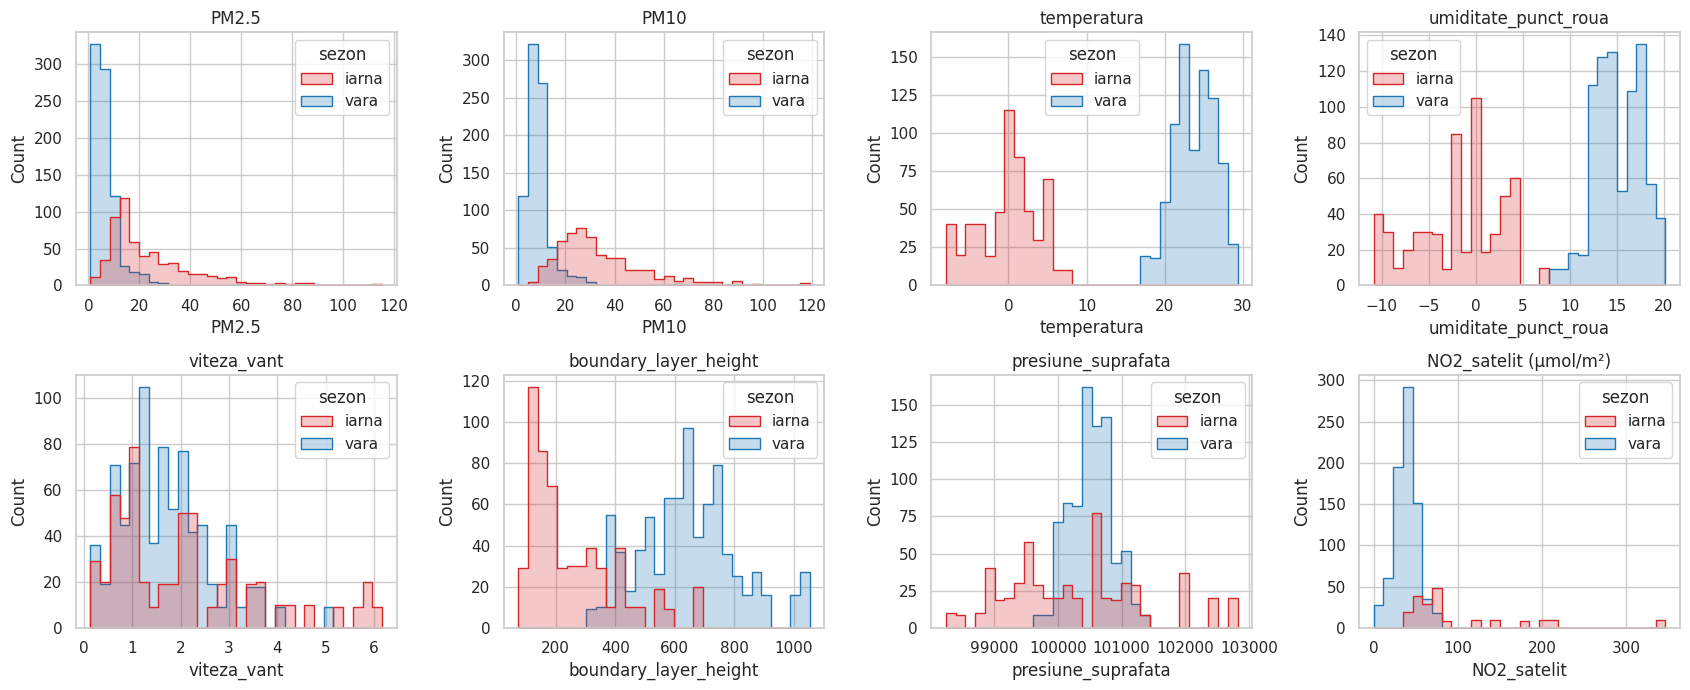

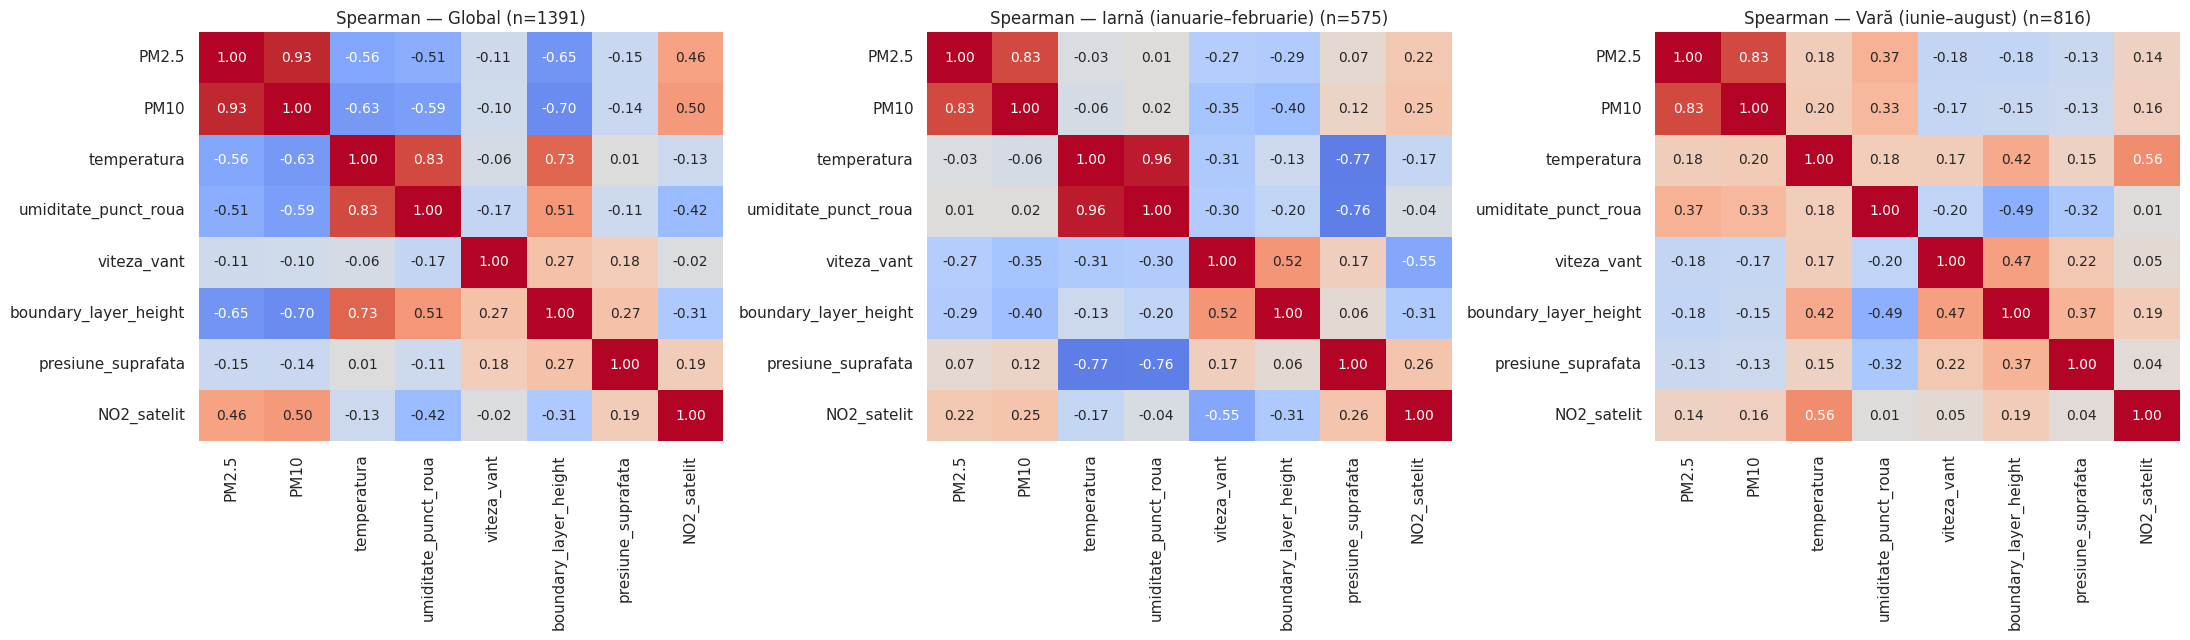

sezon                              iarna        vara
PM2.5                 mean        24.176       6.921
                      median      17.753       5.503
                      std         17.513       6.596
                      min          1.031       0.787
                      max        115.293      91.654
PM10                  mean        34.117       9.140
                      median      29.475       8.289
                      std         18.396       6.992
                      min          1.728       0.787
                      max        119.210     100.149
temperatura           mean        -0.055      23.750
                      median       0.361      23.959
                      std          3.846       2.682
                      min         -7.995      17.415
                      max          7.791      29.318
umiditate_punct_roua  mean        -1.845      15.108
                      median      -1.274      14.959
                      std          4.609       2.533
                      min        -10.874       8.083
                      max          6.944      20.201
viteza_vant           mean         2.086       1.689
                      median       1.766       1.572
                      std          1.557       0.939
                      min          0.164       0.129
                      max          6.165       4.964
boundary_layer_height mean       253.230     641.975
                      median     196.238     639.494
                      std        148.225     166.502
                      min         73.205     314.917
                      max        675.324    1055.046
presiune_suprafata    mean    100304.572  100519.222
                      median  100155.230  100521.125
                      std       1093.119     326.738
                      min      98245.570   99713.230
                      max     102820.870  101321.160
NO2_satelit           mean       102.763      38.632
                      median      71.210      38.564
                      std         74.845      13.784
                      min         40.321       0.000
                      max        346.769      73.704

In [4]:
med_zi = df.groupby('date')['PM2.5'].transform('median')

df['anomalie'] = (df['PM2.5'] / med_zi > 5) & (df['PM2.5'] > 100)
print(f"Rânduri marcate ca anomalie: {df.anomalie.sum()} din {len(df)}")
display(df.loc[df.anomalie, ['date', 'sensor_id', 'PM2.5', 'PM10']].assign(mediana_zilei=med_zi[df.anomalie].round(1)))

# Analiza univariată și bivariată
ok = ~df['anomalie']
brut = df[ok].copy(); brut['NO2_satelit'] *= 1e6                       # doar pentru afișare, µmol/m²
fig, ax = plt.subplots(2, 4, figsize=(17, 7))
for a, c in zip(ax.ravel(), TOATE):
    sns.histplot(data=brut, x=c, hue='sezon', bins=30, element='step', ax=a, palette={'iarna': '#d62728', 'vara': '#1f77b4'})
    a.set_title(c + (' (µmol/m²)' if c == 'NO2_satelit' else ''))
plt.tight_layout(); plt.savefig('cp2_distributii.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(22, 6.5))

for a, (nume, sub) in zip(
    ax,
    [
        ('Global', brut),
        ('Iarnă (ianuarie–februarie)', brut[brut.sezon == 'iarna']),
        ('Vară (iunie–august)', brut[brut.sezon == 'vara'])
    ]
):
    sns.heatmap(
        sub[TOATE].corr(method='spearman'),
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        ax=a,
        cbar=False
    )
    a.set_title(f'Spearman — {nume} (n={len(sub)})')

plt.tight_layout()
plt.savefig('cp2_corelatii_global_si_pe_sezon.png', dpi=200)
plt.show()
display(brut.groupby('sezon')[TOATE].agg(['mean', 'median', 'std', 'min', 'max']).T.round(3))

In [5]:
def transforma(d):
    t = d.copy(); t['NO2_satelit'] = t['NO2_satelit'].clip(lower=0) * 1e6
    for c in ['PM2.5', 'PM10', 'NO2_satelit']: t[c] = np.log1p(t[c])
    return t
df_tf = transforma(df)
df_m = df_tf[~df_tf['anomalie']].copy()

GAP = pd.Timedelta(days=2)
tr = pd.Series(False, index=df_tf.index); te = tr.copy()
for s, g in df_tf.groupby('sezon'):
    d0, d1 = g.date.min(), g.date.max(); cut = d0 + (d1 - d0) * 0.7
    tr |= (df_tf.sezon == s) & (df_tf.date <= cut - GAP)
    te |= (df_tf.sezon == s) & (df_tf.date > cut)
tr_m, te_m = tr.loc[df_m.index], te.loc[df_m.index]
print(f'Split pe zile: train {tr_m.sum()} rânduri · test {te_m.sum()} rânduri · pauză {(~tr_m & ~te_m).sum()} rânduri')

Split pe zile: train 941 rânduri · test 416 rânduri · pauză 34 rânduri


In [6]:
def pca_eval(cols):
    d = df_m.dropna(subset=cols); a_idx, b_idx = tr_m.loc[d.index], te_m.loc[d.index]
    A, B = d.loc[a_idx, cols], d.loc[b_idx, cols]
    sc = StandardScaler().fit(A); A_s, B_s = sc.transform(A), sc.transform(B)   # scalare doar pe train
    full = PCA().fit(A_s); rows = []
    for k in range(1, len(cols)):
        p = PCA(n_components=k).fit(A_s); Z = p.transform(B_s)
        rows.append({'k': k, 'var_cumulata_train_%': round(full.explained_variance_ratio_[:k].sum() * 100, 1),
                     'MSE_reconstructie_test': ((B_s - p.inverse_transform(Z)) ** 2).mean(),
                     'trustworthiness_test': trustworthiness(B_s, Z, n_neighbors=10)})
    comp = pd.crosstab(d.loc[a_idx | b_idx, 'sezon'], np.where(a_idx[a_idx | b_idx], 'train', 'test'))
    return dict(cols=cols, pca=full, m=pd.DataFrame(rows).round(3), n_tr=len(A_s), n_te=len(B_s), comp=comp)

VARIANTE = {'A: senzori + meteo': GRUPURI['Sensor.Community'] + METEO,
            'B: senzori + meteo + S5P (cazuri complete)': TOATE}
VAR_MIN = 80; R, K = {}, {}
for n, c in VARIANTE.items():
    r = R[n] = pca_eval(c)
    ok = r['m'][r['m']['var_cumulata_train_%'] >= VAR_MIN]; K[n] = int(ok['k'].iloc[0]) if len(ok) else int(r['m']['k'].iloc[-1])
    print(f"\n=== {n} — train n={r['n_tr']}, test n={r['n_te']} — k ales = {K[n]} ===")
    display(r['comp']); display(r['m'])


=== A: senzori + meteo — train n=941, test n=416 — k ales = 3 ===


col_0,test,train
sezon,,
iarna,166,389
vara,250,552


,k,var_cumulata_train_%,MSE_reconstructie_test,trustworthiness_test
0,1,56.7,0.695,0.766
1,2,73.7,0.314,0.956
2,3,88.5,0.173,0.982
3,4,96.1,0.065,0.995
4,5,99.0,0.015,0.999
5,6,99.9,0.005,1.000



=== B: senzori + meteo + S5P (cazuri complete) — train n=645, test n=323 — k ales = 3 ===


col_0,test,train
sezon,,
iarna,73,130
vara,250,515


,k,var_cumulata_train_%,MSE_reconstructie_test,trustworthiness_test
0,1,54.0,0.781,0.728
1,2,68.5,0.348,0.944
2,3,81.4,0.256,0.973
3,4,89.3,0.121,0.995
4,5,96.7,0.062,0.996
5,6,99.2,0.015,0.999
6,7,99.9,0.006,1.000


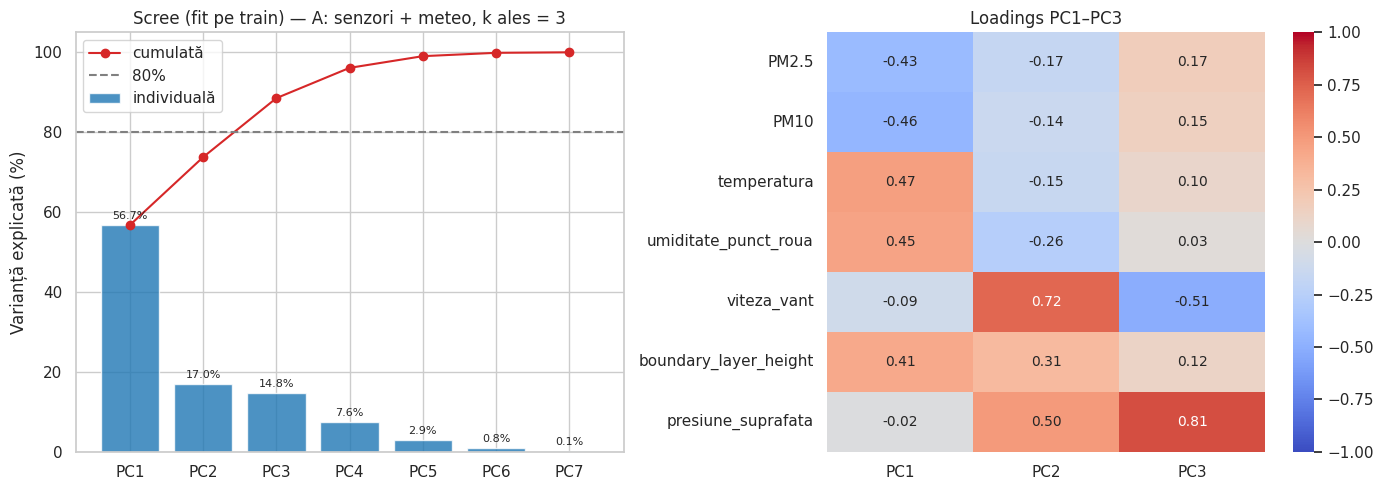

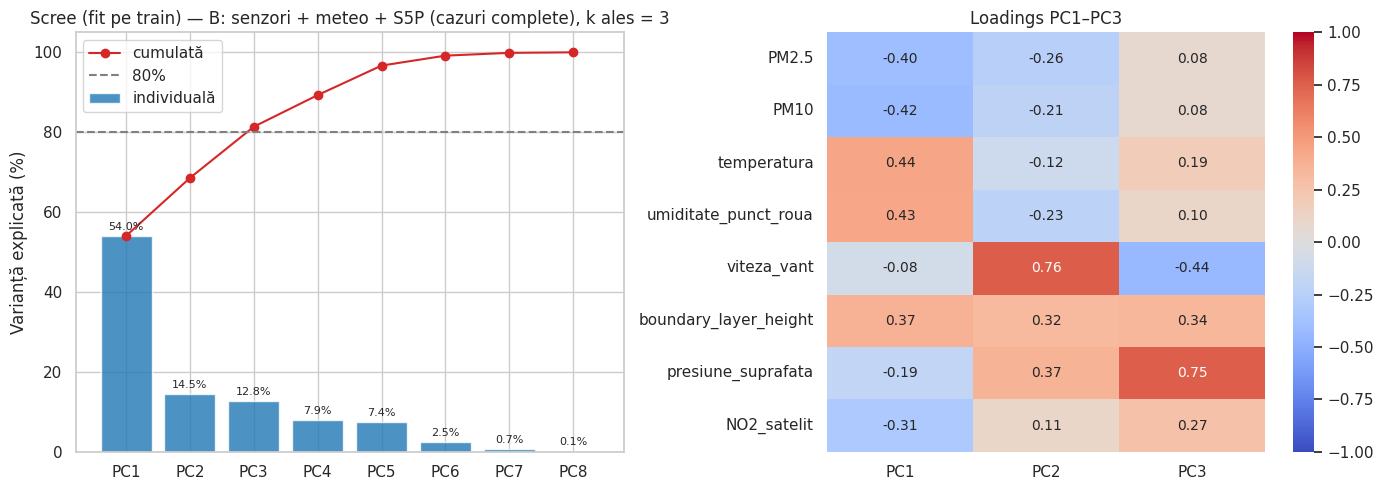

Cele mai mari 3 ponderi (în valoare absolută) pe fiecare componentă. Semnul unei componente e arbitrar;
contează ce trăsături au același semn și care semn opus.

A · PC1: temperatura (+0.47), PM10 (-0.46), umiditate_punct_roua (+0.45)
A · PC2: viteza_vant (+0.72), presiune_suprafata (+0.50), boundary_layer_height (+0.31)
A · PC3: presiune_suprafata (+0.81), viteza_vant (-0.51), PM2.5 (+0.17)
B · PC1: temperatura (+0.44), umiditate_punct_roua (+0.43), PM10 (-0.42)
B · PC2: viteza_vant (+0.76), presiune_suprafata (+0.37), boundary_layer_height (+0.32)
B · PC3: presiune_suprafata (+0.75), viteza_vant (-0.44), boundary_layer_height (+0.34)


In [7]:
for n, r in R.items():
    cols, p = r['cols'], r['pca']; v = p.explained_variance_ratio_ * 100; pcs = [f'PC{i+1}' for i in range(len(cols))]
    L = pd.DataFrame(p.components_.T[:, :3], index=cols, columns=pcs[:3]); r['loadings'] = L
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].bar(pcs, v, color='#1f77b4', alpha=.8, label='individuală'); ax[0].plot(pcs, np.cumsum(v), 'o-', c='#d62728', label='cumulată')
    ax[0].axhline(VAR_MIN, ls='--', c='gray', label=f'{VAR_MIN}%')
    for i, t in enumerate(v): ax[0].annotate(f'{t:.1f}%', (i, t + 1.5), ha='center', fontsize=8)
    ax[0].set(ylabel='Varianță explicată (%)', title=f'Scree (fit pe train) — {n}, k ales = {K[n]}'); ax[0].legend()
    sns.heatmap(L, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title('Loadings PC1–PC3')
    plt.tight_layout(); plt.savefig(f"cp2_pca_{'A' if n.startswith('A') else 'B'}.png", dpi=200); plt.show()

print('Cele mai mari 3 ponderi (în valoare absolută) pe fiecare componentă. Semnul unei componente e arbitrar;')
print('contează ce trăsături au același semn și care semn opus.\n')
for n, r in R.items():
    for pc in ['PC1', 'PC2', 'PC3']:
        top = r['loadings'][pc].reindex(r['loadings'][pc].abs().sort_values(ascending=False).index)[:3]
        print(f"{n[:1]} · {pc}: " + ', '.join(f'{k} ({v:+.2f})' for k, v in top.items()))

,sezon,variabila,lag_0d_spearman,lag_1d_spearman,lag_2d_spearman,lag_3d_spearman,MI_lag0,n_zile
0,iarna,temperatura,-0.221,-0.487,-0.622,-0.571,0.062,39
1,iarna,umiditate_punct_roua,-0.147,-0.413,-0.531,-0.511,0.000,39
2,iarna,viteza_vant,-0.361,-0.136,0.098,0.074,0.122,39
3,iarna,boundary_layer_height,-0.359,-0.194,0.081,0.225,0.131,39
4,iarna,presiune_suprafata,0.362,0.496,0.533,0.492,0.024,39
5,iarna,NO2_satelit,0.363,0.341,0.126,0.407,0.059,13
6,vara,temperatura,0.430,0.395,0.312,0.289,0.172,62
7,vara,umiditate_punct_roua,0.739,0.568,0.325,0.162,0.296,62
8,vara,viteza_vant,-0.201,-0.063,0.215,0.188,0.035,62
9,vara,boundary_layer_height,-0.273,-0.148,0.028,0.072,0.000,62


,pereche,n_zile_train,n_zile_test,r1_train,r1_test,r2_train,r2_test
0,Senzori <-> ERA5,101,46,0.673,0.209,0.157,-0.282
1,Senzori <-> S5P,71,36,0.286,0.146,NaN,NaN
2,ERA5 <-> S5P,71,36,0.410,-0.116,NaN,NaN


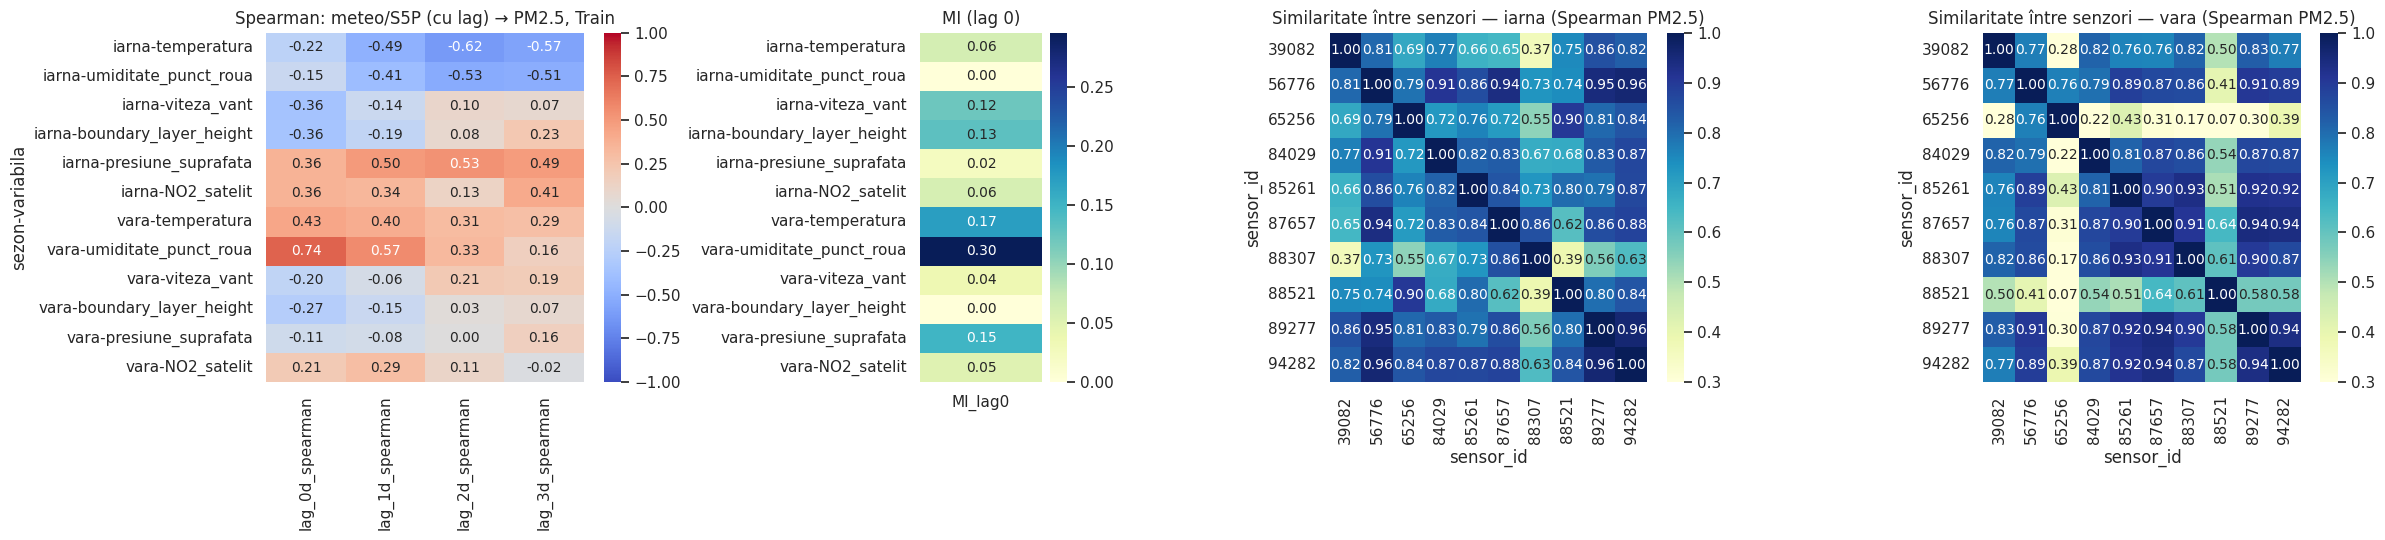

iarna: corelație medie între vecini GPS = 0.761 · între ne-vecini = 0.778
vara: corelație medie între vecini GPS = 0.733 · între ne-vecini = 0.672


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

Tabel principal CP3 — baseline o singură sursă (senzori): PCA vs UMAP, medie ± std pe 5 seed-uri (PCA determinist)


var_expl_train_%  \
perioada       k n_train n_test metoda                            
toată perioada 1 941     416    PCA (baseline)           96.656   
                                UMAP                          —   
iarnă          1 389     166    PCA (baseline)           93.524   
                                UMAP                          —   
vară           1 552     250    PCA (baseline)           94.056   
                                UMAP                          —   

                                               MSE_reconstructie  \
perioada       k n_train n_test metoda                             
toată perioada 1 941     416    PCA (baseline)             0.034   
                                UMAP                           —   
iarnă          1 389     166    PCA (baseline)             0.059   
                                UMAP                           —   
vară           1 552     250    PCA (baseline)             0.073   
                                UMAP                           —   

                                               trustworthiness  \
perioada       k n_train n_test metoda                           
toată perioada 1 941     416    PCA (baseline)           0.954   
                                UMAP             0.976 ± 0.007   
iarnă          1 389     166    PCA (baseline)           0.926   
                                UMAP             0.939 ± 0.030   
vară           1 552     250    PCA (baseline)           0.931   
                                UMAP             0.967 ± 0.005   

                                               corelatie_distante  
perioada       k n_train n_test metoda                             
toată perioada 1 941     416    PCA (baseline)              0.992  
                                UMAP                0.666 ± 0.069  
iarnă          1 389     166    PCA (baseline)              0.964  
                                UMAP                0.638 ± 0.145  
vară           1 552     250    PCA (baseline)              0.973  
                                UMAP                0.383 ± 0.036

In [9]:
# ==============================================================================
# CP3 — RELAȚII ÎNTRE SURSE + PROTOCOL EXPERIMENTAL (baseline pe o singură sursă)
# Se rulează după codul din CP2 (folosește df_m, tr_m, te_m, GRUPURI, METEO, VAR_MIN).
# Pe Kaggle, o singură dată:  !pip install -q umap-learn
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.cross_decomposition import CCA
from sklearn.feature_selection import mutual_info_regression
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

# ------------------------------------------------------------------------------
# PARTEA 1 — HARTA RELAȚIILOR (la nivel de zi, controlat pe sezon, doar zile de Train)
# Se agregă pe zi: cei 10 senzori dintr-o zi împart aceleași valori ERA5/S5P și ar umfla relațiile.
# ------------------------------------------------------------------------------
zi = df_m.groupby('date').agg(
    sezon=('sezon', 'first'),
    PM25=('PM2.5', 'median'),
    PM10=('PM10', 'median'),
    **{c: (c, 'mean') for c in METEO + ['NO2_satelit']}
).sort_index()
zi_tr = zi.loc[zi.index.isin(df_m.loc[tr_m, 'date'].unique())].copy()
zi_te = zi.loc[zi.index.isin(df_m.loc[te_m, 'date'].unique())].copy()

# 1A. Corelație Spearman cu lag (0–3 zile) și informație mutuală (lag 0), separat pe sezon
rows = []
for sez in ['iarna', 'vara']:
    s = zi_tr[zi_tr.sezon == sez]
    for c in METEO + ['NO2_satelit']:
        r = {'sezon': sez, 'variabila': c}
        for lag in range(4):
            x = pd.Series(s[c].reindex(s.index - pd.Timedelta(days=lag)).values, index=s.index)   # valoarea de acum `lag` zile, după dată
            p = pd.DataFrame({'pm': s['PM25'], 'x': x}).dropna()
            r[f'lag_{lag}d_spearman'] = round(spearmanr(p['pm'], p['x'])[0], 3) if len(p) > 5 else np.nan
        p0 = s[['PM25', c]].dropna()
        r['MI_lag0'] = round(mutual_info_regression(p0[[c]], p0['PM25'], random_state=42)[0], 3) if len(p0) > 5 else np.nan
        r['n_zile'] = len(p0)
        rows.append(r)
df_lag = pd.DataFrame(rows)
display(df_lag); df_lag.to_csv('cp3_relatii_lag_mi.csv', index=False)

# 1B. CCA între modalități: centrat pe sezon, fit pe Train, corelații canonice raportate pe Train și pe Test
def run_cca(cols_X, cols_Y, nume):
    tr_s = zi_tr[cols_X + cols_Y + ['sezon']].dropna()
    med = tr_s.groupby('sezon')[cols_X + cols_Y].mean()                      # media pe sezon, doar din Train
    te_s = zi_te[cols_X + cols_Y + ['sezon']].dropna()
    te_s = te_s[te_s['sezon'].isin(med.index)]
    cen = lambda d, cols: d[cols] - med.loc[d['sezon'], cols].to_numpy()
    Xtr, Ytr, Xte, Yte = cen(tr_s, cols_X), cen(tr_s, cols_Y), cen(te_s, cols_X), cen(te_s, cols_Y)
    scX, scY = StandardScaler().fit(Xtr), StandardScaler().fit(Ytr)
    n_comp = min(len(cols_X), len(cols_Y), 2)
    cca = CCA(n_components=n_comp).fit(scX.transform(Xtr), scY.transform(Ytr))
    U1, V1 = cca.transform(scX.transform(Xtr), scY.transform(Ytr))
    U2, V2 = cca.transform(scX.transform(Xte), scY.transform(Yte))
    r = lambda U, V, i: round(np.corrcoef(U[:, i], V[:, i])[0, 1], 3) if i < n_comp else np.nan
    return {'pereche': nume, 'n_zile_train': len(tr_s), 'n_zile_test': len(te_s),
            'r1_train': r(U1, V1, 0), 'r1_test': r(U2, V2, 0), 'r2_train': r(U1, V1, 1), 'r2_test': r(U2, V2, 1)}

df_cca = pd.DataFrame([
    run_cca(['PM25', 'PM10'], METEO, 'Senzori <-> ERA5'),
    run_cca(['PM25', 'PM10'], ['NO2_satelit'], 'Senzori <-> S5P'),
    run_cca(METEO, ['NO2_satelit'], 'ERA5 <-> S5P')])
display(df_cca); df_cca.to_csv('cp3_cca.csv', index=False)

# 1C. Graf kNN spațial între senzori (k = 3 vecini GPS): senzorii vecini au profile PM2.5 mai similare?
corr_sez = {sez: df_m[(df_m.sezon == sez) & tr_m].pivot(index='date', columns='sensor_id', values='PM2.5').corr(method='spearman')
            for sez in ['iarna', 'vara']}
ordine = corr_sez['iarna'].index
corr_sez = {sez: c.loc[ordine, ordine] for sez, c in corr_sez.items()}

# Figura „Harta relațiilor": corelații cu lag + MI, și similaritatea dintre senzori
fig, ax = plt.subplots(1, 4, figsize=(24, 5.5), gridspec_kw={'width_ratios': [1.3, .5, 1.3, 1.3]})
lag_idx = df_lag.set_index(['sezon', 'variabila'])
sns.heatmap(lag_idx[[f'lag_{l}d_spearman' for l in range(4)]], annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title('Spearman: meteo/S5P (cu lag) → PM2.5, Train')
sns.heatmap(lag_idx[['MI_lag0']], annot=True, fmt='.2f', cmap='YlGnBu', ax=ax[1]); ax[1].set_title('MI (lag 0)'); ax[1].set_ylabel('')
for a, sez in zip(ax[2:], ['iarna', 'vara']):
    sns.heatmap(corr_sez[sez], annot=True, fmt='.2f', cmap='YlGnBu', vmin=0.3, vmax=1, ax=a)
    a.set_title(f'Similaritate între senzori — {sez} (Spearman PM2.5)')
plt.tight_layout(); plt.savefig('cp3_harta_relatii.png', dpi=200); plt.show()

if {'lat', 'lon'}.issubset(df_m.columns):
    coord = np.radians(df_m.groupby('sensor_id')[['lat', 'lon']].first().loc[ordine])
    _, idx = NearestNeighbors(n_neighbors=4, metric='haversine').fit(coord).kneighbors(coord)
    vec = [set(r[r != i][:3]) for i, r in enumerate(idx)]                  # 3 vecini GPS ai fiecărui senzor
    for sez, c in corr_sez.items():
        v, nv = [], []
        for i in range(len(ordine)):
            for j in range(i + 1, len(ordine)):
                (v if (j in vec[i] or i in vec[j]) else nv).append(c.iloc[i, j])   # vecinătate simetrică
        print(f"{sez}: corelație medie între vecini GPS = {np.mean(v):.3f} · între ne-vecini = {np.mean(nv):.3f}")
else:
    print("Coloanele 'lat'/'lon' lipsesc din df_m: graful spațial a fost omis.")

# ------------------------------------------------------------------------------
# PARTEA 2 — PROTOCOL EXPERIMENTAL: baseline pe o singură sursă (Sensor.Community)
# PCA (baseline, determinist) vs UMAP (5 seed-uri). Split temporal pe zile, cu pauză (din CP2).
# Metrici: varianță explicată + MSE reconstrucție (doar PCA), trustworthiness (locală), corelația distanțelor (globală).
# Stabilitate: 5 seed-uri și subperioade (iarnă / vară, fiecare cu propriul split).
# ------------------------------------------------------------------------------
COLS = GRUPURI['Sensor.Community']
SEEDS = [0, 1, 2, 3, 4]
PERIOADE = {'toată perioada': None, 'iarnă': 'iarna', 'vară': 'vara'}

def split_scalat(sezon=None):
    d = df_m.dropna(subset=COLS)
    if sezon: d = d[d.sezon == sezon]
    A, B = d.loc[tr_m.loc[d.index], COLS], d.loc[te_m.loc[d.index], COLS]
    sc = StandardScaler().fit(A)                                            # scalare doar pe Train
    return sc.transform(A), sc.transform(B)

corelatie_distante = lambda X, Z: spearmanr(pdist(X), pdist(Z))[0]          # globală: 1 = distanțele între perechi se păstrează

cum = np.cumsum(PCA().fit(split_scalat()[0]).explained_variance_ratio_)    # k: regula de 80% pe Train (ca la CP2), același k pentru UMAP
K = min(int(np.argmax(cum >= VAR_MIN / 100)) + 1, len(COLS) - 1)

rows = []
for per, sezon in PERIOADE.items():
    A_s, B_s = split_scalat(sezon)
    base = dict(perioada=per, k=K, n_train=len(A_s), n_test=len(B_s))
    p = PCA(n_components=K).fit(A_s); Z = p.transform(B_s)
    rows.append({**base, 'metoda': 'PCA (baseline)', 'seed': None,
                 'var_expl_train_%': p.explained_variance_ratio_.sum() * 100,
                 'MSE_reconstructie': ((B_s - p.inverse_transform(Z)) ** 2).mean(),
                 'trustworthiness': trustworthiness(B_s, Z, n_neighbors=10),
                 'corelatie_distante': corelatie_distante(B_s, Z)})
    for sd in SEEDS:
        Z = umap.UMAP(n_components=K, random_state=sd).fit(A_s).transform(B_s)
        rows.append({**base, 'metoda': 'UMAP', 'seed': sd,
                     'trustworthiness': trustworthiness(B_s, Z, n_neighbors=10),
                     'corelatie_distante': corelatie_distante(B_s, Z)})
rez = pd.DataFrame(rows); rez.to_csv('cp3_rezultate_brute.csv', index=False)

def fmt(s):
    s = s.dropna()
    return '—' if s.empty else (f"{s.iloc[0]:.3f}" if len(s) == 1 else f"{s.mean():.3f} ± {s.std():.3f}")
tabel = rez.groupby(['perioada', 'k', 'n_train', 'n_test', 'metoda'], sort=False)[
    ['var_expl_train_%', 'MSE_reconstructie', 'trustworthiness', 'corelatie_distante']].agg(fmt)
print('Tabel principal CP3 — baseline o singură sursă (senzori): PCA vs UMAP, medie ± std pe 5 seed-uri (PCA determinist)')
display(tabel); tabel.to_csv('cp3_tabel_principal.csv')

,sezon,variabila,lag_0d_spearman,lag_1d_spearman,lag_2d_spearman,lag_3d_spearman,MI_lag0,n_zile
0,iarna,temperatura,-0.221,-0.487,-0.622,-0.571,0.062,39
1,iarna,umiditate_punct_roua,-0.147,-0.413,-0.531,-0.511,0.000,39
2,iarna,viteza_vant,-0.361,-0.136,0.098,0.074,0.122,39
3,iarna,boundary_layer_height,-0.359,-0.194,0.081,0.225,0.131,39
4,iarna,presiune_suprafata,0.362,0.496,0.533,0.492,0.024,39
5,iarna,NO2_satelit,0.363,0.341,0.126,0.407,0.059,13
6,vara,temperatura,0.430,0.395,0.312,0.289,0.172,62
7,vara,umiditate_punct_roua,0.739,0.568,0.325,0.162,0.296,62
8,vara,viteza_vant,-0.201,-0.063,0.215,0.188,0.035,62
9,vara,boundary_layer_height,-0.273,-0.148,0.028,0.072,0.000,62


,pereche,n_zile_train,n_zile_test,r1_train,r1_test,r2_train,r2_test
0,Senzori <-> ERA5,101,46,0.673,0.209,0.157,-0.282
1,Senzori <-> S5P,71,36,0.286,0.146,NaN,NaN
2,ERA5 <-> S5P,71,36,0.410,-0.116,NaN,NaN


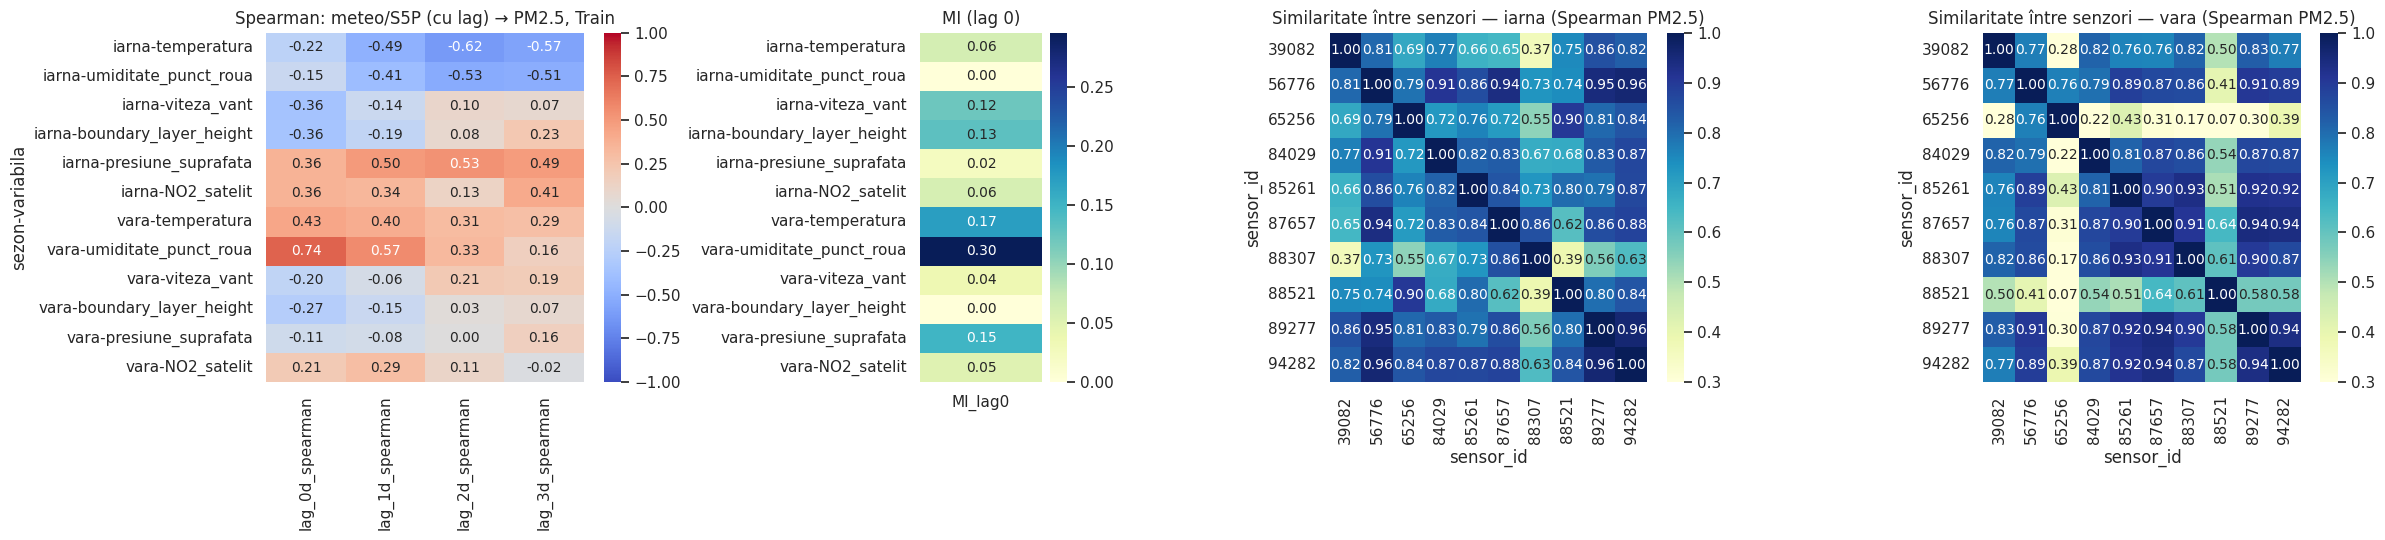

iarna: corelație medie între vecini GPS = 0.761 · între ne-vecini = 0.778
vara: corelație medie între vecini GPS = 0.733 · între ne-vecini = 0.672


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr

Tabel principal CP3 — baseline o singură sursă (senzori), pe test: PCA (determinist) vs UMAP (medie ± std pe 5 seed-uri)


Perioadă,Metodă,n train / test,Varianță explicată (train),MSE reconstrucție,Trustworthiness (local),Corelația distanțelor (global)
toată perioada,PCA,941 / 416,"96,7%","0,034","0,954","0,992"
,UMAP,,—,—,"0,976 ± 0,007","0,666 ± 0,069"
iarnă,PCA,389 / 166,"93,5%","0,059","0,926","0,964"
,UMAP,,—,—,"0,939 ± 0,030","0,638 ± 0,145"
vară,PCA,552 / 250,"94,1%","0,073","0,931","0,973"
,UMAP,,—,—,"0,967 ± 0,005","0,383 ± 0,036"


In [10]:
# ==============================================================================
# CP3 — RELAȚII ÎNTRE SURSE + PROTOCOL EXPERIMENTAL (baseline pe o singură sursă)
# Se rulează după codul din CP2 (folosește df_m, tr_m, te_m, GRUPURI, METEO, VAR_MIN).
# Pe Kaggle, o singură dată:  !pip install -q umap-learn
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.cross_decomposition import CCA
from sklearn.feature_selection import mutual_info_regression
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

# ------------------------------------------------------------------------------
# PARTEA 1 — HARTA RELAȚIILOR (la nivel de zi, controlat pe sezon, doar zile de Train)
# Se agregă pe zi: cei 10 senzori dintr-o zi împart aceleași valori ERA5/S5P și ar umfla relațiile.
# ------------------------------------------------------------------------------
zi = df_m.groupby('date').agg(
    sezon=('sezon', 'first'),
    PM25=('PM2.5', 'median'),
    PM10=('PM10', 'median'),
    **{c: (c, 'mean') for c in METEO + ['NO2_satelit']}
).sort_index()
zi_tr = zi.loc[zi.index.isin(df_m.loc[tr_m, 'date'].unique())].copy()
zi_te = zi.loc[zi.index.isin(df_m.loc[te_m, 'date'].unique())].copy()

# 1A. Corelație Spearman cu lag (0–3 zile) și informație mutuală (lag 0), separat pe sezon
rows = []
for sez in ['iarna', 'vara']:
    s = zi_tr[zi_tr.sezon == sez]
    for c in METEO + ['NO2_satelit']:
        r = {'sezon': sez, 'variabila': c}
        for lag in range(4):
            x = pd.Series(s[c].reindex(s.index - pd.Timedelta(days=lag)).values, index=s.index)   # valoarea de acum `lag` zile, după dată
            p = pd.DataFrame({'pm': s['PM25'], 'x': x}).dropna()
            r[f'lag_{lag}d_spearman'] = round(spearmanr(p['pm'], p['x'])[0], 3) if len(p) > 5 else np.nan
        p0 = s[['PM25', c]].dropna()
        r['MI_lag0'] = round(mutual_info_regression(p0[[c]], p0['PM25'], random_state=42)[0], 3) if len(p0) > 5 else np.nan
        r['n_zile'] = len(p0)
        rows.append(r)
df_lag = pd.DataFrame(rows)
display(df_lag); df_lag.to_csv('cp3_relatii_lag_mi.csv', index=False)

# 1B. CCA între modalități: centrat pe sezon, fit pe Train, corelații canonice raportate pe Train și pe Test
def run_cca(cols_X, cols_Y, nume):
    tr_s = zi_tr[cols_X + cols_Y + ['sezon']].dropna()
    med = tr_s.groupby('sezon')[cols_X + cols_Y].mean()                      # media pe sezon, doar din Train
    te_s = zi_te[cols_X + cols_Y + ['sezon']].dropna()
    te_s = te_s[te_s['sezon'].isin(med.index)]
    cen = lambda d, cols: d[cols] - med.loc[d['sezon'], cols].to_numpy()
    Xtr, Ytr, Xte, Yte = cen(tr_s, cols_X), cen(tr_s, cols_Y), cen(te_s, cols_X), cen(te_s, cols_Y)
    scX, scY = StandardScaler().fit(Xtr), StandardScaler().fit(Ytr)
    n_comp = min(len(cols_X), len(cols_Y), 2)
    cca = CCA(n_components=n_comp).fit(scX.transform(Xtr), scY.transform(Ytr))
    U1, V1 = cca.transform(scX.transform(Xtr), scY.transform(Ytr))
    U2, V2 = cca.transform(scX.transform(Xte), scY.transform(Yte))
    r = lambda U, V, i: round(np.corrcoef(U[:, i], V[:, i])[0, 1], 3) if i < n_comp else np.nan
    return {'pereche': nume, 'n_zile_train': len(tr_s), 'n_zile_test': len(te_s),
            'r1_train': r(U1, V1, 0), 'r1_test': r(U2, V2, 0), 'r2_train': r(U1, V1, 1), 'r2_test': r(U2, V2, 1)}

df_cca = pd.DataFrame([
    run_cca(['PM25', 'PM10'], METEO, 'Senzori <-> ERA5'),
    run_cca(['PM25', 'PM10'], ['NO2_satelit'], 'Senzori <-> S5P'),
    run_cca(METEO, ['NO2_satelit'], 'ERA5 <-> S5P')])
display(df_cca); df_cca.to_csv('cp3_cca.csv', index=False)

# 1C. Graf kNN spațial între senzori (k = 3 vecini GPS): senzorii vecini au profile PM2.5 mai similare?
corr_sez = {sez: df_m[(df_m.sezon == sez) & tr_m].pivot(index='date', columns='sensor_id', values='PM2.5').corr(method='spearman')
            for sez in ['iarna', 'vara']}
ordine = corr_sez['iarna'].index
corr_sez = {sez: c.loc[ordine, ordine] for sez, c in corr_sez.items()}

# Figura „Harta relațiilor": corelații cu lag + MI, și similaritatea dintre senzori
fig, ax = plt.subplots(1, 4, figsize=(24, 5.5), gridspec_kw={'width_ratios': [1.3, .5, 1.3, 1.3]})
lag_idx = df_lag.set_index(['sezon', 'variabila'])
sns.heatmap(lag_idx[[f'lag_{l}d_spearman' for l in range(4)]], annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title('Spearman: meteo/S5P (cu lag) → PM2.5, Train')
sns.heatmap(lag_idx[['MI_lag0']], annot=True, fmt='.2f', cmap='YlGnBu', ax=ax[1]); ax[1].set_title('MI (lag 0)'); ax[1].set_ylabel('')
for a, sez in zip(ax[2:], ['iarna', 'vara']):
    sns.heatmap(corr_sez[sez], annot=True, fmt='.2f', cmap='YlGnBu', vmin=0.3, vmax=1, ax=a)
    a.set_title(f'Similaritate între senzori — {sez} (Spearman PM2.5)')
plt.tight_layout(); plt.savefig('cp3_harta_relatii.png', dpi=200); plt.show()

if {'lat', 'lon'}.issubset(df_m.columns):
    coord = np.radians(df_m.groupby('sensor_id')[['lat', 'lon']].first().loc[ordine])
    _, idx = NearestNeighbors(n_neighbors=4, metric='haversine').fit(coord).kneighbors(coord)
    vec = [set(r[r != i][:3]) for i, r in enumerate(idx)]                  # 3 vecini GPS ai fiecărui senzor
    for sez, c in corr_sez.items():
        v, nv = [], []
        for i in range(len(ordine)):
            for j in range(i + 1, len(ordine)):
                (v if (j in vec[i] or i in vec[j]) else nv).append(c.iloc[i, j])   # vecinătate simetrică
        print(f"{sez}: corelație medie între vecini GPS = {np.mean(v):.3f} · între ne-vecini = {np.mean(nv):.3f}")
else:
    print("Coloanele 'lat'/'lon' lipsesc din df_m: graful spațial a fost omis.")

# ------------------------------------------------------------------------------
# PARTEA 2 — PROTOCOL EXPERIMENTAL: baseline pe o singură sursă (Sensor.Community)
# PCA (baseline, determinist) vs UMAP (5 seed-uri). Split temporal pe zile, cu pauză (din CP2).
# Metrici: varianță explicată + MSE reconstrucție (doar PCA), trustworthiness (locală), corelația distanțelor (globală).
# Stabilitate: 5 seed-uri și subperioade (iarnă / vară, fiecare cu propriul split).
# ------------------------------------------------------------------------------
COLS = GRUPURI['Sensor.Community']
SEEDS = [0, 1, 2, 3, 4]
PERIOADE = {'toată perioada': None, 'iarnă': 'iarna', 'vară': 'vara'}

def split_scalat(sezon=None):
    d = df_m.dropna(subset=COLS)
    if sezon: d = d[d.sezon == sezon]
    A, B = d.loc[tr_m.loc[d.index], COLS], d.loc[te_m.loc[d.index], COLS]
    sc = StandardScaler().fit(A)                                            # scalare doar pe Train
    return sc.transform(A), sc.transform(B)

corelatie_distante = lambda X, Z: spearmanr(pdist(X), pdist(Z))[0]          # globală: 1 = distanțele între perechi se păstrează

cum = np.cumsum(PCA().fit(split_scalat()[0]).explained_variance_ratio_)    # k: regula de 80% pe Train (ca la CP2), același k pentru UMAP
K = min(int(np.argmax(cum >= VAR_MIN / 100)) + 1, len(COLS) - 1)

rows = []
for per, sezon in PERIOADE.items():
    A_s, B_s = split_scalat(sezon)
    base = dict(perioada=per, k=K, n_train=len(A_s), n_test=len(B_s))
    p = PCA(n_components=K).fit(A_s); Z = p.transform(B_s)
    rows.append({**base, 'metoda': 'PCA (baseline)', 'seed': None,
                 'var_expl_train_%': p.explained_variance_ratio_.sum() * 100,
                 'MSE_reconstructie': ((B_s - p.inverse_transform(Z)) ** 2).mean(),
                 'trustworthiness': trustworthiness(B_s, Z, n_neighbors=10),
                 'corelatie_distante': corelatie_distante(B_s, Z)})
    for sd in SEEDS:
        Z = umap.UMAP(n_components=K, random_state=sd).fit(A_s).transform(B_s)
        rows.append({**base, 'metoda': 'UMAP', 'seed': sd,
                     'trustworthiness': trustworthiness(B_s, Z, n_neighbors=10),
                     'corelatie_distante': corelatie_distante(B_s, Z)})
rez = pd.DataFrame(rows); rez.to_csv('cp3_rezultate_brute.csv', index=False)

# ------------------------------------------------------------------------------
# TABELUL PRINCIPAL CP3 — același format ca pe slide 2 (cap de tabel + rânduri PCA / UMAP pe perioade)
# ------------------------------------------------------------------------------
ro = lambda x, nd=3: f"{x:.{nd}f}".replace('.', ',')                        # virgulă zecimală
COL = ['Perioadă', 'Metodă', 'n train / test', 'Varianță\nexplicată (train)', 'MSE\nreconstrucție',
       'Trustworthiness\n(local)', 'Corelația\ndistanțelor (global)']
linii, bold = [], []                                                         # bold: celulele câștigătoare (diferență > std-ul UMAP)
for per in PERIOADE:
    p_ = rez[(rez.perioada == per) & (rez.metoda == 'PCA (baseline)')].iloc[0]
    u_ = rez[(rez.perioada == per) & (rez.metoda == 'UMAP')]
    b_p, b_u = [False] * 7, [False] * 7
    for j, m in ((5, 'trustworthiness'), (6, 'corelatie_distante')):
        if abs(u_[m].mean() - p_[m]) > u_[m].std():
            (b_u if u_[m].mean() > p_[m] else b_p)[j] = True
    linii += [[per, 'PCA', f"{int(p_.n_train)} / {int(p_.n_test)}", ro(p_['var_expl_train_%'], 1) + '%',
               ro(p_.MSE_reconstructie), ro(p_.trustworthiness), ro(p_.corelatie_distante)],
              ['', 'UMAP', '', '—', '—', f"{ro(u_.trustworthiness.mean())} ± {ro(u_.trustworthiness.std())}",
               f"{ro(u_.corelatie_distante.mean())} ± {ro(u_.corelatie_distante.std())}"]]
    bold += [b_p, b_u]

tabel = pd.DataFrame(linii, columns=[c.replace('\n', ' ') for c in COL])
print('Tabel principal CP3 — baseline o singură sursă (senzori), pe test: PCA (determinist) vs UMAP (medie ± std pe 5 seed-uri)')
display(tabel.style.hide(axis='index')); tabel.to_csv('cp3_tabel_principal.csv', index=False)